# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado dois datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro paineis solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.

**NOTA**: Ambos os datasets são refetentes ao mês de setembro de 2018.  

In [1]:
#CÉLULA TCC-01
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#CÉLULA TCC-
# Método responsável por carregar os arquivos csv's
def loadDataFile(fileName):
    #Convertendo a coluna de data para index e para o formato de DateTime
    return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])    

In [3]:
#CÉLULA TCC-
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [8]:
#CÉLULA TCC-
dfRawFoto = loadDataFile('input/Fotovoltaico_Sep_2018.csv') 
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4320 entries, 2018-09-01 00:00:00 to 2018-09-30 23:50:00
Data columns (total 9 columns):
painel                     4320 non-null float64
energia_dia                4320 non-null float64
potencia                   4320 non-null float64
deficit_vapor_vmedio       4320 non-null float64
precipitacao_valor         4320 non-null float64
radiacao_solar_valor       4320 non-null float64
temperatura_ar_vmedio      4320 non-null float64
umidade_ar_vmedio          4320 non-null float64
velocidade_vento_vmedio    4320 non-null float64
dtypes: float64(9)
memory usage: 337.5 KB


In [9]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâne, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

KeyError: "labels ['energia_ano' 'solarnet_led' 'solarweb_led' 'power_led' 'energia_total'] not contained in axis"

In [19]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [20]:
#CÉLULA TCC-06
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [21]:
#CÉLULA TCC-06
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-09-30 23:58:49.283,1.0,42950.0,0.0
2018-09-30 23:58:28.620,1.0,42950.0,0.0
2018-09-30 23:58:12.723,1.0,42950.0,0.0
2018-09-30 23:58:07.320,1.0,42950.0,0.0
2018-09-30 23:57:48.903,1.0,42950.0,0.0


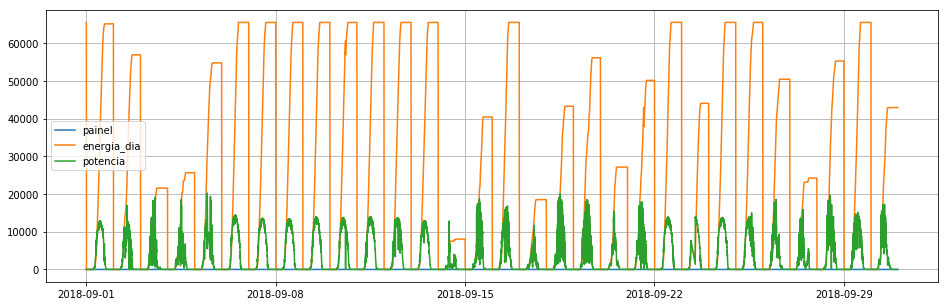

In [40]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.grid()
showDataPlot(dfRawFoto1)
##Dividir gráficos

## 1.2 - Análise do dataset meteorológicos

In [28]:
#CÉLULA TCC-
dfRawMete = loadDataFile('input/Meteorologico_Sep_2018.csv') 
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4297 entries, 2018-09-30 23:50:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         4297 non-null float64
deficit_vapor_vmedio       4297 non-null float64
ponto_orvalho_vmin         4297 non-null float64
ponto_orvalho_vmedio       4297 non-null float64
precipitacao_valor         4297 non-null float64
radiacao_solar_valor       4297 non-null float64
temperatura_ar_vmin        4297 non-null float64
temperatura_ar_vmedio      4297 non-null float64
temperatura_ar_vmax        4297 non-null float64
umidade_ar_vmin            4297 non-null float64
umidade_ar_vmedio          4297 non-null float64
umidade_ar_vmax            4297 non-null float64
velocidade_vento_vmedio    4297 non-null float64
velocidade_vento_vmax      4297 non-null float64
dtypes: float64(14)
memory usage: 503.6 KB


In [29]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    'ponto_orvalho_vmin',
    'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    'temperatura_ar_vmin',
    #'temperatura_ar_vmedio',
    'temperatura_ar_vmax',
    'umidade_ar_vmin',
    #'umidade_ar_vmedio',
    'umidade_ar_vmax',
    #'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [30]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [33]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,
2018-09-30 23:50:06,0.25,0.0,0.0,20.80,89.56,0.0
2018-09-30 23:40:07,0.26,0.0,0.0,20.93,88.94,0.2
2018-09-30 23:30:06,0.27,0.0,0.0,21.00,88.99,0.0
2018-09-30 23:20:07,0.27,0.0,0.0,21.06,89.00,0.0
2018-09-30 23:10:06,0.25,0.0,0.0,20.94,89.66,0.0


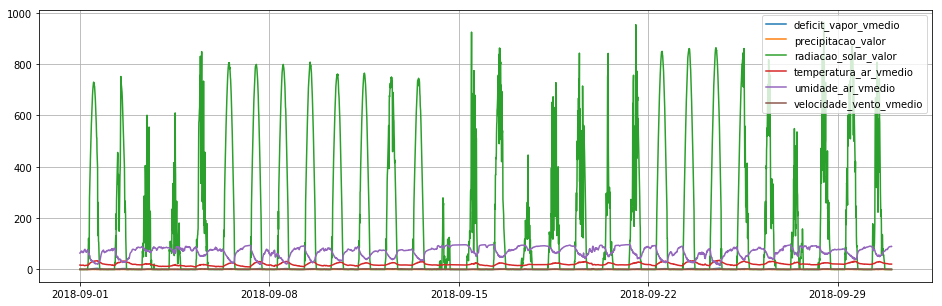

In [39]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
plt.grid()
showDataPlot(dfRawMete)
##Dividir gráficos

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes como:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes para um mesmo padrão de tempo nos dois datasets.

## 1.3.1 - DownSample

In [56]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample('10T') #de 10 em 10 minutos cravados
newDownFoto = downFoto.mean()
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  energia_dia  potencia
data                                              
2018-09-01 00:00:00     1.0      65530.0       0.0
2018-09-01 00:10:00     1.0      45871.0       0.0
2018-09-01 00:20:00     1.0          0.0       0.0
2018-09-01 00:30:00     1.0          0.0       0.0
2018-09-01 00:40:00     1.0          0.0       0.0


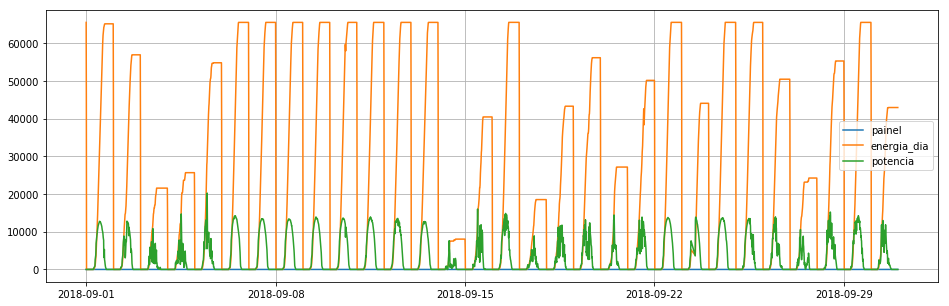

In [59]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownFoto)
##Dividir gráficos

## 1.3.2 - UpSample

In [50]:
#CÉLULA TCC-
downMete = dfRawMete.resample('10T') #de 10 em 10 minutos cravados
newDownMete = downMete.mean()
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head()

,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,
2018-09-01 00:00:00,0.700,0.0,0.0,17.14,63.81,0.0
2018-09-01 00:10:00,0.685,0.0,0.0,17.01,64.34,0.0
2018-09-01 00:20:00,0.670,0.0,0.0,16.88,64.87,0.0
2018-09-01 00:30:00,0.640,0.0,0.0,16.95,66.34,0.0
2018-09-01 00:40:00,0.660,0.0,0.0,17.23,66.36,0.0


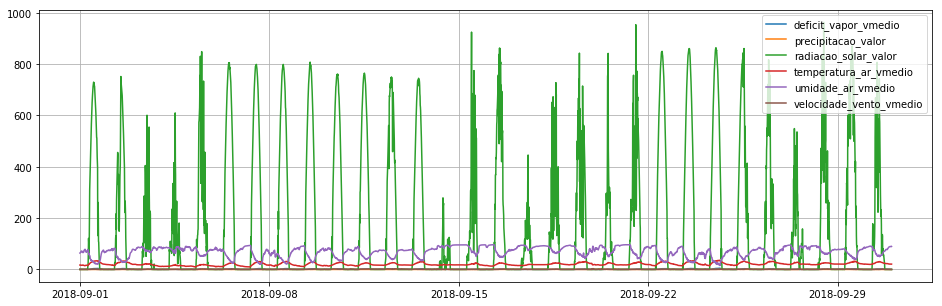

In [60]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownMete)
##Dividir gráficos

## 1.3.3 - Realizando o merge

In [74]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
dfSet1.reset_index(inplace=True)

In [77]:
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 10 columns):
data                       4320 non-null datetime64[ns]
painel                     4320 non-null float64
energia_dia                4320 non-null float64
potencia                   4320 non-null float64
deficit_vapor_vmedio       4320 non-null float64
precipitacao_valor         4320 non-null float64
radiacao_solar_valor       4320 non-null float64
temperatura_ar_vmedio      4320 non-null float64
umidade_ar_vmedio          4320 non-null float64
velocidade_vento_vmedio    4320 non-null float64
dtypes: datetime64[ns](1), float64(9)
memory usage: 337.6 KB


In [84]:
dfSet1.head()
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

,data,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
0,2018-09-01 00:00:00,1.0,65530.0,0.0,0.700,0.0,0.0,17.14,63.81,0.0
1,2018-09-01 00:10:00,1.0,45871.0,0.0,0.685,0.0,0.0,17.01,64.34,0.0
2,2018-09-01 00:20:00,1.0,0.0,0.0,0.670,0.0,0.0,16.88,64.87,0.0
3,2018-09-01 00:30:00,1.0,0.0,0.0,0.640,0.0,0.0,16.95,66.34,0.0
4,2018-09-01 00:40:00,1.0,0.0,0.0,0.660,0.0,0.0,17.23,66.36,0.0


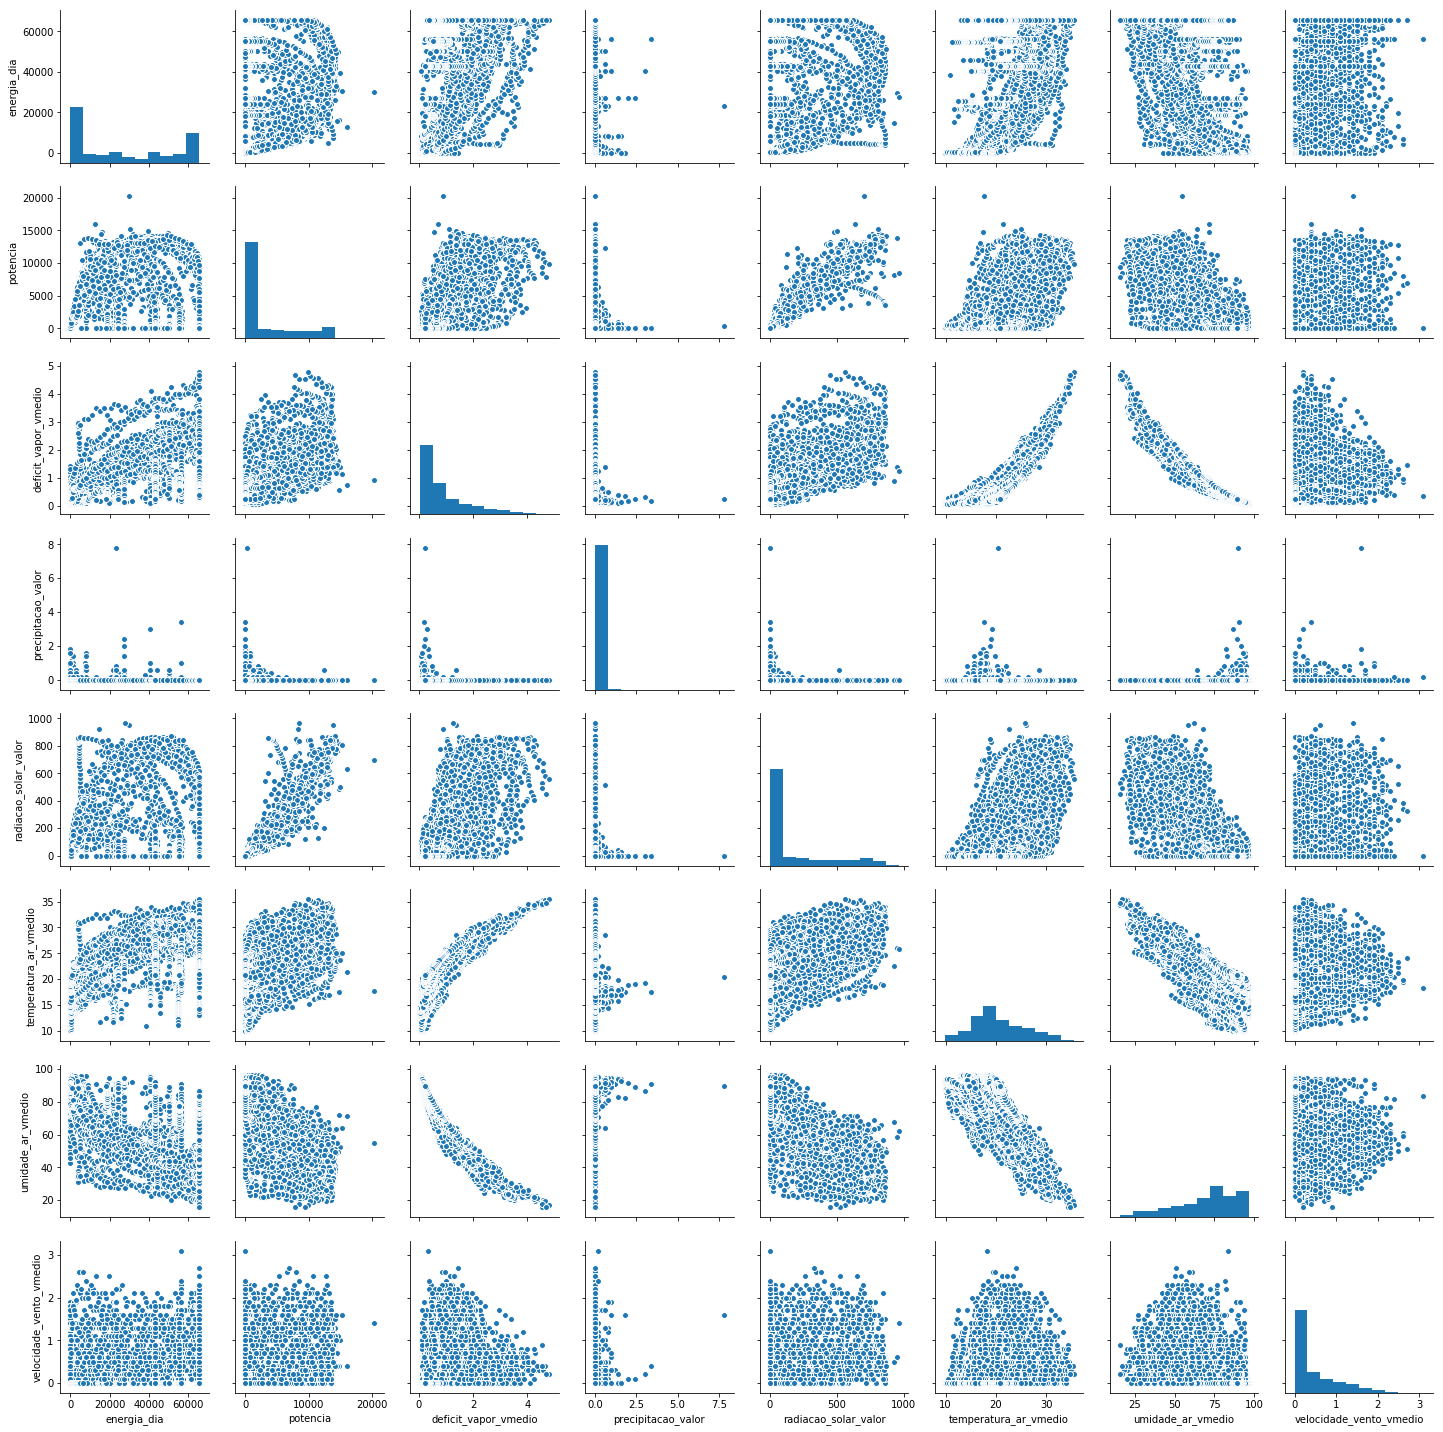

In [87]:
import seaborn as sns

dfSeaborn = dfSet1.drop(columns=['painel'])
g = sns.pairplot(dfSeaborn)

## 2 - Normalização

## 3 - Treinamento do modelo

## 4 - Resultados

In [103]:
df = loadDataFile('FotoMet_P1_Sep_2018.csv')
df.head()

,painel,energia_dia,potencia,deficit_vapor_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmedio,umidade_ar_vmedio,velocidade_vento_vmedio
data,,,,,,,,,
2018-09-01 00:00:00,1.0,65530.0,0.0,0.700,0.0,0.0,17.14,63.81,0.0
2018-09-01 00:10:00,1.0,45871.0,0.0,0.685,0.0,0.0,17.01,64.34,0.0
2018-09-01 00:20:00,1.0,0.0,0.0,0.670,0.0,0.0,16.88,64.87,0.0
2018-09-01 00:30:00,1.0,0.0,0.0,0.640,0.0,0.0,16.95,66.34,0.0
2018-09-01 00:40:00,1.0,0.0,0.0,0.660,0.0,0.0,17.23,66.36,0.0


In [98]:
#df.describe()
df = df.reset_index()

## Criação das variáveis X e y para início da separação dos dados, na variável X foram apagadas as colunas consideradas irrelevantes

In [105]:
X = df.drop(['painel','radiacao_solar_valor','potencia'],axis=1)
y = df['energia_dia']

In [86]:
y.head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: potencia, dtype: float64

## Normalização dos dados utilizando MinMaxScaler, e separação dos dados em treino e teste

In [106]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

min_max_scaler = MinMaxScaler()

df[df.columns] = min_max_scaler.fit_transform(df[df.columns])




In [93]:
X = df.drop(['data','painel','radiacao_solar_valor','potencia'],axis=1)
y = df['potencia']

In [94]:
from sklearn.linear_model import LinearRegression

In [107]:
# separando os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)


ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
5       0.0
6       0.0
7       0.0
8       0.0
9       0.0
10      0.0
11      0.0
12      0.0
13      0.0
14      0.0
15      0.0
16      0.0
17      0.0
18      0.0
19      0.0
20      0.0
21      0.0
22      0.0
23      0.0
24      0.0
25      0.0
26      0.0
27      0.0
28      0.0
29      0.0
       ... 
4290    0.0
4291    0.0
4292    0.0
4293    0.0
4294    0.0
4295    0.0
4296    0.0
4297    0.0
4298    0.0
4299    0.0
4300    0.0
4301    0.0
4302    0.0
4303    0.0
4304    0.0
4305    0.0
4306    0.0
4307    0.0
4308    0.0
4309    0.0
4310    0.0
4311    0.0
4312    0.0
4313    0.0
4314    0.0
4315    0.0
4316    0.0
4317    0.0
4318    0.0
4319    0.0
Name: potencia, Length: 4320, dtype: float64